In [3]:
### load packages ###
import os
import csv
import logging
import matplotlib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm
from multiprocessing import Pool, cpu_count
from collections import defaultdict
from Bio import SeqIO
from Bio.Seq import Seq
from Bio import pairwise2
from Bio.pairwise2 import format_alignment
from Bio.Align import PairwiseAligner
import edlib
import matplotlib.patheffects as patheffects
import matplotlib.patches as mpatches

/cluster/software/stacks/2024-05/python-cuda/3.11.6/lib/python3.11/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [4]:
### Load TR regions and extract consensus unit sequences ###

def load_genomes(genome_dir):
    genome_seqs = {}
    for fname in os.listdir(genome_dir):
        if fname.endswith('.fna') or fname.endswith('.fasta'):
            genome_name = os.path.splitext(fname)[0]
            contigs = {}
            for record in SeqIO.parse(os.path.join(genome_dir, fname), 'fasta'):
                # Take only the first word of the header as contig ID
                contig_id = record.id.split()[0]
                contigs[contig_id] = record.seq
            genome_seqs[genome_name] = contigs
    return genome_seqs

def get_genome_lengths(genome_seqs):
    # Sum lengths of all contigs per genome for absolute length
    genome_lengths = {}
    for genome, contigs in genome_seqs.items():
        total_len = sum(len(seq) for seq in contigs.values())
        genome_lengths[genome] = total_len
    return genome_lengths

def parse_bed_line(line):
    parts = line.strip().split("\t")
    contig = parts[0]
    start = int(parts[1])
    end = int(parts[2])
    label = parts[3]
    strand = parts[5]
    block_sizes = list(map(int, parts[10].split(","))) if parts[10] else []
    block_starts = list(map(int, parts[11].split(","))) if parts[11] else []
    return contig, start, end, label, strand, block_sizes, block_starts

def extract_tr_regions(bed_dir, genome_seqs):
    genome_trs = defaultdict(list)
    for bed_file in os.listdir(bed_dir):
        if not bed_file.endswith(".bed"):
            continue
            
        # FIX: Clean the name exactly the same way as selected_genomes
        base = bed_file.replace(".tandem-repeats.bed", "").replace(".fna", "").replace(".fasta", "")
        #base = os.path.splitext(base)[0] ##################################################### depending on your file names and header, comment this line out or not.
        full_path = os.path.join(bed_dir, bed_file)

        with open(full_path) as f:
            for line in f:
                if line.startswith("#") or not line.strip():
                    continue
                contig, start, end, label, strand, block_sizes, block_starts = parse_bed_line(line)
                units = []
                for size, rel_start in zip(block_sizes, block_starts):
                    abs_start = start + rel_start
                    abs_end = abs_start + size
                    try:
                        seq = genome_seqs[base][contig][abs_start:abs_end]
                        if strand == "-":
                            seq = seq.reverse_complement()
                        units.append(str(seq))
                    except KeyError:
                        print(f"Warning: missing contig {contig} in genome {base}")
                        continue

                if not units:
                    print(f"Warning: no units extracted for region {contig}:{start}-{end} in genome {base}")
                    continue

                region_seq = "".join(units)
                genome_trs[base].append({
                    "contig": contig,
                    "start": start,
                    "end": end,
                    "strand": strand,
                    "units": units,
                    "unit_count": len(units),
                    "unit_seq": units[0],
                    "region_seq": region_seq
                    })
        print(f"Extracted {len(genome_trs[base])} TR regions for genome {base}")
    return genome_trs

In [5]:
### Compare regions across genomes (unit-sequence based - accounting for frame shifts and reverse compl.) ###

# Set up logging (suppress match-level output)
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
DEBUG_MATCHES = False  # Toggle this to True if you want per-match logging

# Configure aligner
aligner = PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = 0
aligner.extend_gap_score = 0

def all_rotations(seq):
    """Generate all circular rotations of a sequence."""
    return [seq[i:] + seq[:i] for i in range(len(seq))]

def are_unit_sequences_equivalent(seq1, seq2, identity_threshold=1.0):
    """Check if seq1 is equivalent to seq2 (or its reverse complement) with rotations."""
    seq2_rc = str(Seq(seq2).reverse_complement())
    best_identity = 0
    best_match = (False, None, None, None)

    for i, s1_variant in enumerate(all_rotations(seq1)):
        for j, s2_variant in enumerate(all_rotations(seq2)):
            identity = aligner.score(s1_variant, s2_variant) / max(len(s1_variant), len(s2_variant))
            if identity > best_identity:
                best_identity = identity
                best_match = (True, i, j, '+')
                if identity >= identity_threshold:
                    return best_match

        for j, s2_variant in enumerate(all_rotations(seq2_rc)):
            identity = aligner.score(s1_variant, s2_variant) / max(len(s1_variant), len(s2_variant))
            if identity > best_identity:
                best_identity = identity
                best_match = (True, i, j, '-')
                if identity >= identity_threshold:
                    return best_match

    return best_match if best_identity >= identity_threshold else (False, None, None, None)

def compare_tr_pairs(args):
    """Worker function for multiprocessing pool."""
    g1, g2, tr1, tr2, threshold = args
    match, rot1, rot2, strand = are_unit_sequences_equivalent(tr1["unit_seq"], tr2["unit_seq"], identity_threshold=threshold)
    if match:
        if DEBUG_MATCHES:
            logging.info(f"MATCH: {g1} vs {g2} | strand={strand}, rot1={rot1}, rot2={rot2}")
        return {
            "genome1": g1,
            "contig1": tr1["contig"],
            "start1": tr1["start"],
            "end1": tr1["end"],
            "unit_count1": tr1["unit_count"],
            "unit_seq1": tr1["unit_seq"],
            "rotation1": rot1,

            "genome2": g2,
            "contig2": tr2["contig"],
            "start2": tr2["start"],
            "end2": tr2["end"],
            "unit_count2": tr2["unit_count"],
            "unit_seq2": tr2["unit_seq"],
            "rotation2": rot2,
            "strand": strand,

            "same_unit_count": tr1["unit_count"] == tr2["unit_count"]
        }
    return None

def find_shared_trs_parallel(genome_trs, threshold=1.0, processes=None):
    if processes is None:
        processes = max(1, cpu_count() - 1)

    logging.info("Preparing TR pair comparison tasks...")
    tasks = []
    genomes = list(genome_trs.keys())

    for i in range(len(genomes)):
        g1 = genomes[i]
        for j in range(i + 1, len(genomes)):
            g2 = genomes[j]
            for tr1 in genome_trs[g1]:
                for tr2 in genome_trs[g2]:
                    tasks.append((g1, g2, tr1, tr2, threshold))

    logging.info(f"Total TR pairs to compare: {len(tasks)}")

    shared = []
    with Pool(processes=processes) as pool:
        for result in pool.imap_unordered(compare_tr_pairs, tasks, chunksize=100):
            if result:
                shared.append(result)

    logging.info(f"Total shared TRs found: {len(shared)}")
    return shared

def get_unique_tr_regions(genome_trs, shared_pairs):
    # All TR regions as (genome, contig, start, end)
    all_tr_set = set()
    for genome, trs in genome_trs.items():
        for tr in trs:
            all_tr_set.add((genome, tr["contig"], tr["start"], tr["end"]))
    
    # All connected TR regions in shared pairs
    connected_tr_set = set()
    for pair in shared_pairs:
        connected_tr_set.add((pair["genome1"], pair["contig1"], pair["start1"], pair["end1"]))
        connected_tr_set.add((pair["genome2"], pair["contig2"], pair["start2"], pair["end2"]))

    # Unique TR regions = all - connected
    unique_tr_set = all_tr_set - connected_tr_set
    return unique_tr_set

def save_unique_tr_regions_to_csv(unique_tr_regions, genome_trs, output_file):
    # unique_tr_regions is a set of (genome, contig, start, end)
    # genome_trs has the detailed info of TRs per genome

    # Prepare list of dicts for CSV writing
    rows = []
    for genome, contig, start, end in unique_tr_regions:
        # Find the TR info in genome_trs for this exact TR region
        tr_info = next(
            (tr for tr in genome_trs.get(genome, [])
             if tr["contig"] == contig and tr["start"] == start and tr["end"] == end),
            None
        )
        if tr_info is None:
            continue

        row = {
            "genome": genome,
            "contig": contig,
            "start": start,
            "end": end,
            "unit_seq": tr_info.get("unit_seq", ""),
            "unit_count": tr_info.get("unit_count", ""),
            # Add any other info fields from tr_info you want here
        }
        rows.append(row)

    # Write to CSV
    fieldnames = ["genome", "contig", "start", "end", "unit_seq", "unit_count"]
    with open(output_file, 'w', newline='') as csvfile:
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()
        for r in rows:
            writer.writerow(r)

    print(f"Saved {len(rows)} unique TR regions to {output_file}")



def normalize_tr_positions(genome_trs, genome_seqs, genome_lengths):
    all_trs_scaled = {}
    for genome, trs in genome_trs.items():
        contigs = genome_seqs.get(genome, {})
        genome_len = genome_lengths.get(genome, 1)
        positions_scaled = []
        for tr in trs:
            contig = tr["contig"]
            contig_seq = contigs.get(contig)
            if contig_seq is None:
                continue
            contig_len = len(contig_seq)
            midpoint = (tr["start"] + tr["end"]) / 2
            norm_pos = midpoint / contig_len  # normalized within contig
            # To scale along genome line, estimate contig start offset in genome:
            # We'll sum previous contigs lengths in alphabetical order as rough offset
            contig_names_sorted = sorted(contigs.keys())
            contig_index = contig_names_sorted.index(contig)
            contig_offset = sum(len(contigs[c]) for c in contig_names_sorted[:contig_index])
            # Absolute position in genome:
            abs_pos = contig_offset + midpoint
            # Scale to genome length:
            scaled_pos = abs_pos / genome_len
            positions_scaled.append(scaled_pos)
        all_trs_scaled[genome] = positions_scaled
    return all_trs_scaled


# ---------------------------------------------------------
# Cluster TRs within a genome to remove duplicates
# ---------------------------------------------------------
def cluster_trs_within_genome(trs):
    """
    Cluster TRs by biological unit sequence (account for rotations + RC).
    Returns:
        clusters: list of clusters, each cluster = list of TR dicts
        tr_to_cluster: maps (contig,start,end) -> cluster_id
    """
    clusters = []
    tr_to_cluster = {}
    for tr in trs:
        key = (tr["contig"], tr["start"], tr["end"])
        placed = False
        for i, cluster in enumerate(clusters):
            rep = cluster[0]
            same, _, _, _ = are_unit_sequences_equivalent(
                tr["unit_seq"], rep["unit_seq"], identity_threshold=1.0
            )
            if same:
                cluster.append(tr)
                tr_to_cluster[key] = i
                placed = True
                break
        if not placed:
            clusters.append([tr])
            tr_to_cluster[key] = len(clusters)-1
    return clusters, tr_to_cluster

# ---------------------------------------------------------
# Step 1: compute shared percentage matrix
# ---------------------------------------------------------
def compute_shared_percentage_matrix_unique(genome_trs, shared_trs):
    genomes = sorted(genome_trs.keys())

    # Cluster TRs within each genome
    genome_clusters = {}
    tr_to_cluster = {}
    total_trs = {}
    for g in genomes:
        clusters, mapping = cluster_trs_within_genome(genome_trs[g])
        genome_clusters[g] = clusters
        tr_to_cluster[g] = mapping
        total_trs[g] = len(clusters)  # count unique TR sequences per genome

    # Build shared_dict using cluster IDs
    shared_dict = defaultdict(lambda: defaultdict(set))
    for match in shared_trs:
        if match is None:
            continue
        g1, g2 = match["genome1"], match["genome2"]
        k1 = (match["contig1"], match["start1"], match["end1"])
        k2 = (match["contig2"], match["start2"], match["end2"])
        c1 = tr_to_cluster[g1][k1]
        c2 = tr_to_cluster[g2][k2]
        shared_dict[g1][g2].add(c1)
        shared_dict[g2][g1].add(c2)

    # Build matrix
    shared_matrix = pd.DataFrame(index=genomes, columns=genomes, dtype=float)
    for g1 in genomes:
        for g2 in genomes:
            shared_count = len(shared_dict[g1][g2])
            shared_matrix.loc[g1, g2] = 100.0 * shared_count / total_trs[g1] if total_trs[g1] > 0 else 0.0

    return shared_matrix, shared_dict, total_trs

# ---------------------------------------------------------
# Step 2: Export table consistent with clustermap
# ---------------------------------------------------------
def export_shared_percentage_table_from_matrix(shared_matrix, out_csv):
    records = []
    for g1 in shared_matrix.index:
        for g2 in shared_matrix.columns:
            records.append({
                "genome1": g1,
                "genome2": g2,
                "%TRs_in_genome1": shared_matrix.loc[g1, g2],
                "%TRs_in_genome2": shared_matrix.loc[g2, g1],
            })
    df = pd.DataFrame(records)
    df.to_csv(out_csv, index=False)
    print(f"Saved shared TR table: {out_csv}")
    return df

In [7]:
### Plot clustermap

def plot_clustermap(shared_matrix, genome_to_organism=None, figsize=(14, 14), save_path=None):

    # Rename genomes if mapping is provided
    if genome_to_organism:
        shared_matrix = shared_matrix.rename(index=genome_to_organism,
                                             columns=genome_to_organism)

    # Mask diagonal
    mask = np.eye(len(shared_matrix), dtype=bool)

    # Color map
    cmap = sns.color_palette("Blues", as_cmap=True)
    cmap.set_bad("lightgray")

    # Plot clustermap
    g = sns.clustermap(
        shared_matrix.astype(float),
        annot=False,                 
        cmap=cmap,
        linewidths=0.5,
        linecolor='gray',
        figsize=figsize,             
        cbar_kws={"label": "Shared TRs (%)"},
        mask=mask
    )

    # Rotate labels
    g.ax_heatmap.set_xticklabels(
        g.ax_heatmap.get_xticklabels(),
        rotation=90,
        ha='center'
    )
    g.ax_heatmap.set_yticklabels(
        g.ax_heatmap.get_yticklabels(),
        rotation=0
    )

    # Ensure all labels fit
    plt.setp(g.ax_heatmap.xaxis.get_majorticklabels(), fontsize=10)
    plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), fontsize=10)

    # Adjust margins so labels are not cut off
    g.fig.subplots_adjust(top=0.98, bottom=0.05, left=0.05, right=0.95)

    # Colorbar styling
    g.cax.tick_params(labelsize=5)
    g.cax.set_ylabel("Shared TRs (%)", fontsize=10)

    # Save figure
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

In [8]:
### Run the full analysis ###

# Set your directories here
out_dir = "/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/TR_similarity"
os.makedirs(out_dir, exist_ok=True)

bed_dir = Path("/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/bed_files/")
genome_dir = Path("/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/genomes/")

# Metadata 
#file that connects file names with organism names
mapping_file = "/cluster/project/umbiol/projects/methanogens/Assembly-accessions_to_Organism-names.txt"
df = pd.read_csv(mapping_file, sep='\t', header=None, names=['genome', 'organism'])
genome_to_organism = dict(zip(df['genome'], df['organism']))

# Get selected genome names without .fna extension
selected_genomes = sorted([
    f.name.replace(".fna", "").replace(".fasta", "") 
    for f in genome_dir.glob("*") 
    if f.suffix in [".fna", ".fasta"]
])

# === RUN ===
# Load genome sequences
genome_seqs = load_genomes(genome_dir)
# Extract TR regions from BED files
genome_trs_full = extract_tr_regions(bed_dir, genome_seqs)
# Filter only selected genomes
genome_trs = {g: genome_trs_full[g] for g in selected_genomes if g in genome_trs_full}
print("Filtered genome_trs keys after applying selected_genomes filter:", list(genome_trs.keys()))
# Find shared TR regions
shared_trs = find_shared_trs_parallel(genome_trs, threshold=1.0)
# compute shared TRs matrix (for cluster map)
shared_matrix, shared_dict, total_trs = compute_shared_percentage_matrix_unique(genome_trs, shared_trs)
csv_path = os.path.join(out_dir, "shared_tr_percentages.csv")
export_shared_percentage_table_from_matrix(shared_matrix, csv_path)

# === save table ===
shared_df = pd.DataFrame(shared_trs)
shared_df.to_csv(os.path.join(out_dir, "shared_TR_table.csv"), index=False)

2026-11-04 16:27:32,736 - INFO - Preparing TR pair comparison tasks...


Extracted 168 TR regions for genome GCA_000007065.1_ASM706v1_genomic
Extracted 172 TR regions for genome GCA_000007345.1_ASM734v1_genomic
Extracted 157 TR regions for genome GCA_000970205.1_ASM97020v1_genomic
Extracted 327 TR regions for genome GCA_001027005.1_ASM102700v1_genomic
Extracted 162 TR regions for genome GCA_025035885.1_ASM2503588v1_genomic
Extracted 4 TR regions for genome GCF_000016525.1_ASM1652v1_genomic
Extracted 78 TR regions for genome GCF_001563245.1_ASM156324v1_genomic
Extracted 158 TR regions for genome GCF_032594095.1
Extracted 64 TR regions for genome GCF_032594115.1
Extracted 140 TR regions for genome GCF_032594355.1
Extracted 29 TR regions for genome GCF_032594435.1
Extracted 280 TR regions for genome GCF_032594355.1
Extracted 60 TR regions for genome GCF_000024185.1_ASM2418v1_genomic
Filtered genome_trs keys after applying selected_genomes filter: ['GCA_000007065.1_ASM706v1_genomic', 'GCA_000007345.1_ASM734v1_genomic', 'GCA_000970205.1_ASM97020v1_genomic', 'GCA

2026-11-04 16:27:33,884 - INFO - Total TR pairs to compare: 1209325
Process ForkPoolWorker-86:
Process ForkPoolWorker-71:
Process ForkPoolWorker-104:

KeyboardInterrupt



In [11]:
### the code below is importing the computed results from the cells above and generates plots

# directories
out_dir = "/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/TR_similarity"
os.makedirs(out_dir, exist_ok=True)

bed_dir = Path("/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/bed_files/")
genome_dir = Path("/cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/genomes/")

# Metadata 
#file that connects file names with organism names
mapping_file = "/cluster/project/umbiol/projects/methanogens/Assembly-accessions_to_Organism-names.txt"
df = pd.read_csv(mapping_file, sep='\t', header=None, names=['genome', 'organism'])
genome_to_organism = dict(zip(df['genome'], df['organism']))

# Get selected genome names without .fna extension
selected_genomes = sorted([
    f.name.replace(".fna", "").replace(".fasta", "") 
    for f in genome_dir.glob("*") 
    if f.suffix in [".fna", ".fasta"]
])


# === RUN (OPTIMIZED: NO RE-COMPUTING) ===

# 1. Load genome sequences (Still needed for lengths/offsets)
genome_seqs = load_genomes(genome_dir)

# 2. Extract TR regions from BED files
genome_trs_full = extract_tr_regions(bed_dir, genome_seqs)

# 3. Filter only selected genomes
# Ensure selected_genomes includes both .fna and .fasta based on our previous fix
genome_trs = {g: genome_trs_full[g] for g in selected_genomes if g in genome_trs_full}
print("Filtered genome_trs keys:", list(genome_trs.keys()))

# 4. LOAD shared TRs from CSV instead of calculating
shared_csv_input = os.path.join(out_dir, "shared_TR_table.csv")

if os.path.exists(shared_csv_input):
    print(f"Loading shared TR data from {shared_csv_input}...")
    # Convert CSV back to the list of dicts format expected by shared_trs
    shared_trs = pd.read_csv(shared_csv_input).to_dict('records')
    
    # DYNAMIC FILTER: 
    # Since you want the plot/matrix to update when you change 'selected_genomes',
    # we filter the loaded CSV data to only keep rows where BOTH genomes are in our list.
    shared_trs = [
        match for match in shared_trs 
        if match['genome1'] in genome_trs and match['genome2'] in genome_trs
    ]
    print(f"Loaded and filtered {len(shared_trs)} shared TR relationships.")
else:
    print("ERROR: shared_TR_table.csv not found. You must run the calculation once first.")

# 5. Compute matrix and export (using the loaded data)
#shared_matrix, shared_dict, total_trs = compute_shared_percentage_matrix_unique(genome_trs, shared_trs)

#csv_output_path = os.path.join(out_dir, "shared_tr_percentages.csv")
#export_shared_percentage_table_from_matrix(shared_matrix, csv_output_path)

Extracted 168 TR regions for genome GCA_000007065.1_ASM706v1_genomic
Extracted 172 TR regions for genome GCA_000007345.1_ASM734v1_genomic
Extracted 157 TR regions for genome GCA_000970205.1_ASM97020v1_genomic
Extracted 327 TR regions for genome GCA_001027005.1_ASM102700v1_genomic
Extracted 162 TR regions for genome GCA_025035885.1_ASM2503588v1_genomic
Extracted 4 TR regions for genome GCF_000016525.1_ASM1652v1_genomic
Extracted 78 TR regions for genome GCF_001563245.1_ASM156324v1_genomic
Extracted 158 TR regions for genome GCF_032594095.1
Extracted 64 TR regions for genome GCF_032594115.1
Extracted 140 TR regions for genome GCF_032594355.1
Extracted 29 TR regions for genome GCF_032594435.1
Extracted 280 TR regions for genome GCF_032594355.1
Extracted 60 TR regions for genome GCF_000024185.1_ASM2418v1_genomic
Filtered genome_trs keys: ['GCA_000007065.1_ASM706v1_genomic', 'GCA_000007345.1_ASM734v1_genomic', 'GCA_000970205.1_ASM97020v1_genomic', 'GCA_001027005.1_ASM102700v1_genomic', 'GCA

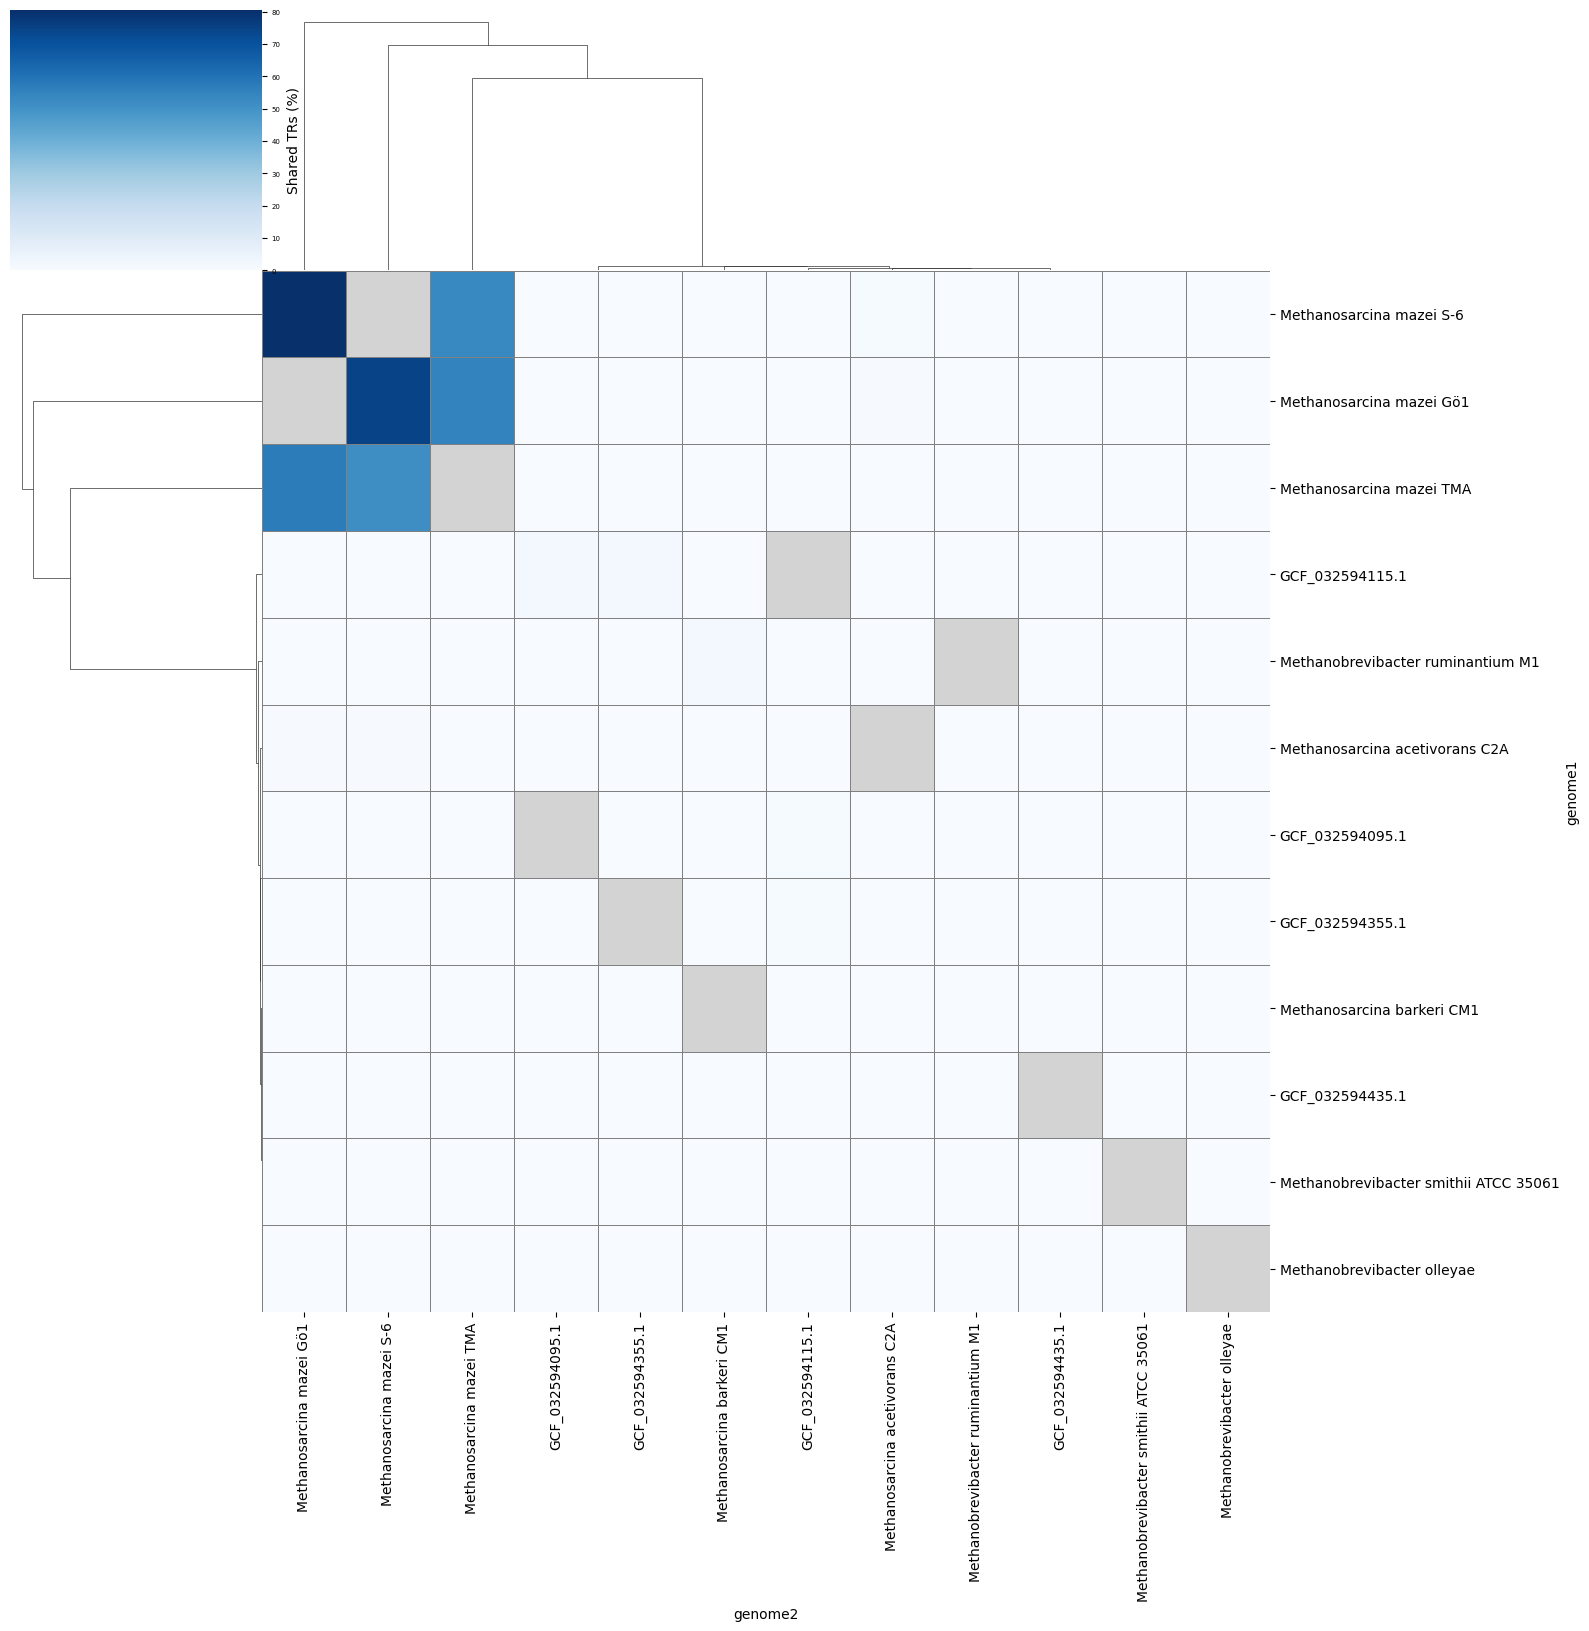

In [18]:
### plot the clustermap
csv_path = os.path.join(out_dir, "shared_tr_percentages.csv")
df = pd.read_csv(csv_path)
# Pivot directly into the square matrix required by plot_clustermap()
shared_matrix = df.pivot(
    index="genome1", 
    columns="genome2", 
    values="%TRs_in_genome1"
).astype(float)

# Plot without re-running the pipeline
plot_clustermap(
    shared_matrix, 
    genome_to_organism=genome_to_organism, 
    figsize=(14, 14), 
    save_path=os.path.join(out_dir, "tr_clustermap.pdf")
)

Plot successfully saved to: /cluster/project/umbiol/projects/methanogens/methanogens_252/tree_fig_2/TR_similarity/clean_plot_final.svg


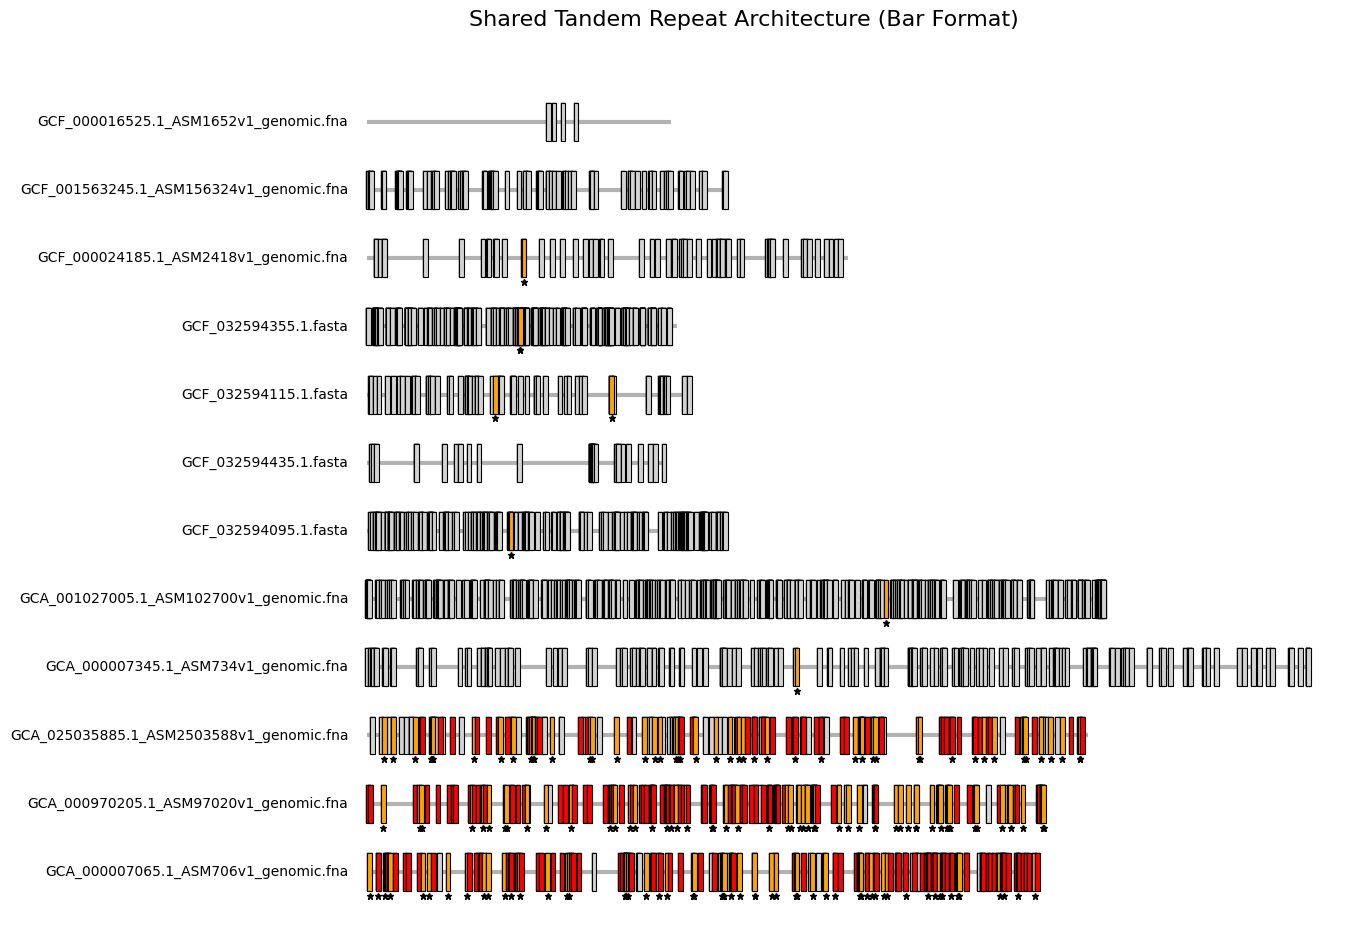

In [12]:
### Plot shared TRs for Main Fig. 2 ###

genome_lengths = get_genome_lengths(genome_seqs)

# Font settings
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
matplotlib.rcParams['svg.fonttype'] = 'path' 
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.family'] = 'sans-serif'

# --- SETTINGS ---
keep_genomes = [
    'GCA_000007065.1_ASM706v1_genomic.fna', 
    'GCA_000970205.1_ASM97020v1_genomic.fna', 
    'GCA_025035885.1_ASM2503588v1_genomic.fna',
    'GCA_000007345.1_ASM734v1_genomic.fna',
    'GCA_001027005.1_ASM102700v1_genomic.fna', 
    'GCF_032594095.1.fasta',     
    'GCF_032594435.1.fasta',
    'GCF_032594115.1.fasta',    
    'GCF_032594355.1.fasta',
    'GCF_000024185.1_ASM2418v1_genomic.fna',
    'GCF_001563245.1_ASM156324v1_genomic.fna', 
    'GCF_000016525.1_ASM1652v1_genomic.fna', 
]

# --- 1. LOAD & FILTER DATA ---
shared_df = pd.read_csv(os.path.join(out_dir, "shared_TR_table.csv"))

# We clean the names for comparison logic
def clean_n(name):
    return name.replace(".fna", "").replace(".fasta", "").strip()

clean_keep = [clean_n(g) for g in keep_genomes]

# Filter rows where both genome1 and genome2 (cleaned) are in our clean list
mask = shared_df['genome1'].apply(clean_n).isin(clean_keep) & \
       shared_df['genome2'].apply(clean_n).isin(clean_keep)
filtered_shared = shared_df[mask].to_dict('records')

# Build tr_status using cleaned keys to ensure matches
tr_status = {}
for row in filtered_shared:
    # We use the raw name from the CSV as the key base
    k1 = (row["genome1"], row["contig1"], row["start1"], row["end1"])
    k2 = (row["genome2"], row["contig2"], row["start2"], row["end2"])
    color = "red" if row["same_unit_count"] else "orange"
    for k in [k1, k2]:
        if tr_status.get(k) != "orange": 
            tr_status[k] = color

def plot_from_csv_centered(genome_order, tr_data_dict, genome_lens, genome_seqs_dict, save_filename="clean_plot_final.svg"):
    # --- VISUAL PARAMETERS ---
    TR_HEIGHT = 0.5           # Vertical thickness of the bar
    SPACING = 1.8             # Vertical gap between genomes
    DEFAULT_GRAY = "#D3D3D3"
    
    # VISIBILITY BOOST: Ensure bars are at least 0.5% of the total view width
    # This prevents tiny TRs from disappearing or being too thin to see color.
    MIN_WIDTH_PERCENT = 0.005 

    plt.figure(figsize=(14, len(genome_order) * 0.8))
    ax = plt.gca()
    
    all_known_lens = [v for v in genome_lens.values()]
    max_len_global = max(all_known_lens) if all_known_lens else 1e6
    min_visual_width = max_len_global * MIN_WIDTH_PERCENT

    for i, g_raw in enumerate(genome_order):
        y_pos = float(i * SPACING)
        
        g_base = clean_n(g_raw)
        tr_key = next((k for k in tr_data_dict.keys() if clean_n(k) == g_base), None)
        seq_key = next((k for k in genome_seqs_dict.keys() if clean_n(k) == g_base), None)
        len_key = next((k for k in genome_lens.keys() if clean_n(k) == g_base), None)

        # 1. Genome Backbone
        curr_len = genome_lens.get(len_key, max_len_global)
        ax.hlines(y_pos, 0, curr_len, color='black', linewidth=3, alpha=0.3, zorder=1)
        
        # 2. Genome Name
        display_name = genome_to_organism.get(g_raw, g_raw)
        ax.text(-max_len_global * 0.02, y_pos, display_name, 
                ha='right', va='center', fontsize=10)

        if not tr_key or not seq_key:
            continue

        # 3. Plot TRs as Rectangular Bars
        for tr in tr_data_dict[tr_key]:
            # Position calculation
            contigs = genome_seqs_dict[seq_key]
            midpoint = (tr["start"] + tr["end"]) / 2
            if tr["contig"] in contigs:
                c_names = sorted(contigs.keys())
                offset = sum(len(contigs[c]) for c in c_names[:c_names.index(tr["contig"])])
                abs_pos = offset + midpoint
            else:
                abs_pos = midpoint

            # Appearance
            lookup_key = (tr_key, tr["contig"], tr["start"], tr["end"])
            fill_color = tr_status.get(lookup_key, DEFAULT_GRAY)
            
            # --- WIDTH LOGIC ---
            real_width = tr["end"] - tr["start"]
            visual_width = max(real_width, min_visual_width) # Boost if too small
            
            # --- GEOMETRY: Centered Rectangle ---
            # Vertices: [Bottom-Left, Top-Left, Top-Right, Bottom-Right]
            x_coords = [abs_pos - visual_width/2, abs_pos - visual_width/2, 
                        abs_pos + visual_width/2, abs_pos + visual_width/2]
            y_coords = [y_pos - TR_HEIGHT, y_pos + TR_HEIGHT, 
                        y_pos + TR_HEIGHT, y_pos - TR_HEIGHT]
            
            # Draw the bar
            poly = ax.fill(x_coords, y_coords, color=fill_color, 
                           ec='black', lw=0.8, zorder=10 if fill_color != DEFAULT_GRAY else 5)
            
            # Apply a very subtle stroke to define the edges
            plt.setp(poly, path_effects=[patheffects.withStroke(linewidth=0.3, foreground='black')])

            # 4. Marker for "Orange" status
            if fill_color == "orange":
                ax.plot(abs_pos, y_pos - (SPACING * 0.35), 
                        marker="*", color="black", markersize=5, zorder=12)

    # Styling
    plt.rcParams['svg.fonttype'] = 'path'
    ax.set_xlim(-max_len_global * 0.25, max_len_global * 1.05)
    ax.set_ylim(-SPACING, len(genome_order) * SPACING)
    ax.axis("off")
    
    plt.title("Shared Tandem Repeat Architecture (Bar Format)", fontsize=16, pad=20)
    plt.tight_layout()
    # --- SAVE LOGIC ---
    save_path = os.path.join(out_dir, save_filename)
    plt.savefig(save_path, 
                format='svg', 
                bbox_inches='tight', 
                transparent=True, 
                dpi=300)
    
    print(f"Plot successfully saved to: {save_path}")
    plt.show()

# Run
plot_from_csv_centered(keep_genomes, genome_trs, genome_lengths, genome_seqs)